<a href="https://colab.research.google.com/github/viniciuscristall-spec/MLAM_Global_Solution/blob/main/Global_Solution_MLAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CitizenTech - Global Solution MLAM

André Debiazzi - RM569062

Kaique da Silva - RM572718

Vinicius Cristal - RM572049

## Problema e objetivo

**Desafio CitizenTech (tema: campo).** A produção agrícola sustenta milhares de comunidades rurais, mas varia muito de uma região para outra. Este trabalho usa dados reais para investigar **como a área cultivada se relaciona com o valor da produção agrícola das microrregiões brasileiras** e se é possível prever e classificar esse valor a partir das áreas plantada e colhida.

**Objetivo das análises:** (i) caracterizar a distribuição do valor da produção; (ii) testar hipóteses sobre a área colhida; (iii) medir e modelar a relação entre área e valor (regressão linear simples e múltipla); (iv) classificar microrregiões de alto e baixo valor de produção (regressão logística binária).

## Base de dados

- **Fonte:** IBGE - SIDRA, Pesquisa Agrícola Municipal (PAM), tabela 1612 - https://sidra.ibge.gov.br/tabela/1612
- **Arquivo:** `tabela1612.csv` (dados reais). O produto e o ano de referência constam no cabeçalho do arquivo, impresso na seção 1.
- **Unidade de análise:** microrregião geográfica.
- **Variáveis:** Área plantada (hectares), Área colhida (hectares) e Valor da produção (mil reais).
- **Justificativa:** base oficial e pública, com variáveis quantitativas reais que permitem aplicar probabilidade, testes de hipóteses, correlação e regressões, e que se relacionam diretamente com o desenvolvimento do campo.

### Configuração do ambiente

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, r2_score
from sklearn.preprocessing import StandardScaler

SEED = 42  # reprodutibilidade das amostras aleatórias


def forca_correlacao(r):
    """Classifica a intensidade de uma correlação linear."""
    a = abs(r)
    if a >= 0.9:
        return 'muito forte'
    if a >= 0.7:
        return 'forte'
    if a >= 0.5:
        return 'moderada'
    if a >= 0.3:
        return 'fraca'
    return 'muito fraca'


def teste_f(r2, n, k):
    """Teste F de significância global da regressão (k variáveis explicativas)."""
    f_stat = (r2 / k) / ((1 - r2) / (n - k - 1))
    return f_stat, stats.f.sf(f_stat, k, n - k - 1)

### 1. Importação e Tratamento dos Dados

In [2]:
URL_BASE = 'https://raw.githubusercontent.com/viniciuscristall-spec/MLAM_Global_Solution/refs/heads/main/tabela1612.csv'
ARQUIVO = 'tabela1612.csv'

# Baixa a base original uma única vez (se ainda não estiver na pasta do notebook)
if not os.path.exists(ARQUIVO):
    urllib.request.urlretrieve(URL_BASE, ARQUIVO)

# Cabeçalho do arquivo SIDRA: identifica a tabela, o produto e o ano de referência
with open(ARQUIVO, encoding='utf-8-sig') as f:
    for _ in range(3):
        print(f.readline().strip())

df = pd.read_csv(ARQUIVO, sep=';', skiprows=3, encoding='utf-8-sig')
print(f'\nO DataFrame possui {df.shape[0]} registros e {df.shape[1]} atributos.')

"Tabela 1612 - Área plantada, área colhida, quantidade produzida, rendimento médio e valor da produção das lavouras temporárias"
"Mesorregião Geográfica e Microrregião Geográfica";"Ano x Variável x Produto das lavouras temporárias"
"Mesorregião Geográfica e Microrregião Geográfica";"2025"

O DataFrame possui 695 registros e 4 atributos.


In [3]:
df = df.rename(columns={
    'Mesorregião Geográfica e Microrregião Geográfica': 'Regiao',
    'Área plantada (Hectares)': 'Área_plantada',
    'Área colhida (Hectares)': 'Área_colhida',
    'Valor da produção (Mil Reais)': 'Valor_producao',
})
colunas = ['Área_plantada', 'Área_colhida', 'Valor_producao']

# Conversão numérica única. Na legenda do SIDRA, '-' é zero; outros símbolos ('X', '...') viram NaN.
for col in colunas:
    df[col] = pd.to_numeric(df[col].replace('-', 0), errors='coerce')

# A tabela traz 137 mesorregiões seguidas de 558 microrregiões (totais das mesorregiões = soma das
# microrregiões). Misturar os dois níveis contaria cada região duas vezes; a verificação abaixo confirma.
N_MESO = 137
soma_meso = df['Valor_producao'].iloc[:N_MESO].sum()
soma_micro = df['Valor_producao'].iloc[N_MESO:].sum()
print(f'Soma do valor da produção - mesorregiões: {soma_meso:,.0f} | microrregiões: {soma_micro:,.0f}')

if len(df) > N_MESO and np.isclose(soma_meso, soma_micro, rtol=1e-3):
    df = df.iloc[N_MESO:]
    print(f'Os dois níveis se repetem: mantidas apenas as {len(df)} microrregiões (unidade de análise).')
else:
    print('ATENÇÃO: a base não segue o padrão mesorregiões + microrregiões; conferir o arquivo.')

n_antes = len(df)
df = df.dropna(subset=colunas).reset_index(drop=True)
print(f'Registros removidos por valores ausentes/omitidos: {n_antes - len(df)} | Registros analisados: {len(df)}\n')
print(df[colunas].describe().round(2))
df.head()

Soma do valor da produção - mesorregiões: 719,926,221 | microrregiões: 719,926,401
Os dois níveis se repetem: mantidas apenas as 558 microrregiões (unidade de análise).
Registros removidos por valores ausentes/omitidos: 3 | Registros analisados: 555

       Área_plantada  Área_colhida  Valor_producao
count         555.00        555.00          555.00
mean       172132.53     170918.26      1297164.69
std        408133.11     408368.50      2973577.92
min             6.00          6.00          137.00
25%         10639.50       8886.50        67141.50
50%         42404.00      37472.00       332200.00
75%        151402.00     151402.00      1316035.50
max       4730741.00    4730741.00     34961535.00


,Regiao,Área_plantada,Área_colhida,Valor_producao
0,Porto Velho (RO),244991.0,243395.0,1890428.0
1,Guajará-Mirim (RO),73299.0,73279.0,494948.0
2,Ariquemes (RO),200326.0,200290.0,1312683.0
3,Ji-Paraná (RO),23766.0,23748.0,261392.0
4,Alvorada D'Oeste (RO),92497.0,91768.0,642923.0


### 2. Distribuição Normal de Probabilidade

In [4]:
# Variável escolhida: Valor da produção (mil reais)
variavel = df['Valor_producao']
media = variavel.mean()
mediana = variavel.median()
desvio_padrao = variavel.std(ddof=0)  # desvio padrão populacional
assimetria = variavel.skew()
print(f'Média: {media:,.2f} | Mediana: {mediana:,.2f} | Desvio padrão: {desvio_padrao:,.2f} | Assimetria: {assimetria:.2f}')


def classificar_evento(p):
    if p == 0:
        return 'evento impossível'
    if p == 1:
        return 'evento certo'
    if np.isclose(p, 0.5):
        return 'evento equiprovável'
    return 'evento provável' if p > 0.5 else 'evento improvável'


# a) P(X < média)
p_a = stats.norm.cdf(media, loc=media, scale=desvio_padrao)
print(f'\n[Item 2a] P(X < média) = {p_a:.2%} -> {classificar_evento(p_a)}')

# b) P(X > mediana)
p_b = stats.norm.sf(mediana, loc=media, scale=desvio_padrao)
print(f'[Item 2b] P(X > mediana) = {p_b:.2%} -> {classificar_evento(p_b)}')

print('\nInterpretação:')
print('- Na normal, a média divide a distribuição ao meio, então P(X < média) = 50% (equiprovável).')
posicao = 'abaixo' if mediana < media else 'acima'
print(f'- A mediana ({mediana:,.0f}) está {posicao} da média ({media:,.0f}); por isso, sob normalidade, '
      f'P(X > mediana) = {p_b:.2%}.')
if assimetria > 1:
    print(f'- Os dados reais são fortemente assimétricos à direita (assimetria = {assimetria:.2f}) e a proporção '
          f'observada acima da mediana é {(variavel > mediana).mean():.0%}. A normalidade é, portanto, uma '
          'hipótese de trabalho, e as probabilidades acima devem ser lidas como aproximações.')

Média: 1,297,164.69 | Mediana: 332,200.00 | Desvio padrão: 2,970,897.82 | Assimetria: 6.29

[Item 2a] P(X < média) = 50.00% -> evento equiprovável
[Item 2b] P(X > mediana) = 62.73% -> evento provável

Interpretação:
- Na normal, a média divide a distribuição ao meio, então P(X < média) = 50% (equiprovável).
- A mediana (332,200) está abaixo da média (1,297,165); por isso, sob normalidade, P(X > mediana) = 62.73%.
- Os dados reais são fortemente assimétricos à direita (assimetria = 6.29) e a proporção observada acima da mediana é 50%. A normalidade é, portanto, uma hipótese de trabalho, e as probabilidades acima devem ser lidas como aproximações.


### 3. Testes de Hipóteses para a Média

In [5]:
# Variável escolhida: Área colhida (hectares). Referência: média e desvio padrão populacionais dos dados.
area_colhida = df['Área_colhida']
mu_ref = area_colhida.mean()
sigma_ref = area_colhida.std(ddof=0)
print(f'Média de referência: {mu_ref:,.2f} ha | Desvio padrão populacional: {sigma_ref:,.2f} ha\n')


def teste_z_media(n, alpha, cauda):
    amostra = area_colhida.sample(n=n, random_state=SEED)
    media_amostral = amostra.mean()
    z = (media_amostral - mu_ref) / (sigma_ref / np.sqrt(n))
    if cauda == 'menor':
        simbolo, z_crit = '<', stats.norm.ppf(alpha)
        p_valor, rejeita = stats.norm.cdf(z), z < z_crit
    else:
        simbolo, z_crit = '>', stats.norm.ppf(1 - alpha)
        p_valor, rejeita = stats.norm.sf(z), z > z_crit
    print(f'H0: μ = {mu_ref:,.2f}  |  H1: μ {simbolo} {mu_ref:,.2f}')
    print(f'n = {n} | α = {alpha:.0%} | média amostral = {media_amostral:,.2f}')
    print(f'Z calculado = {z:.4f} | Z crítico = {z_crit:.4f} | p-valor = {p_valor:.4f}')
    if rejeita:
        print(f'Decisão: rejeita H0. Há evidência, a {alpha:.0%} de significância, de que a média é {cauda} que a de referência.\n')
    else:
        print(f'Decisão: não rejeita H0. Não há evidência, a {alpha:.0%} de significância, de que a média seja {cauda} que a de referência.\n')


print('[Item 3a]')
teste_z_media(n=20, alpha=0.06, cauda='menor')
print('[Item 3b]')
teste_z_media(n=25, alpha=0.09, cauda='maior')
print('Observação: as amostras saem da própria base de referência, então H0 é verdadeira por construção; '
      'a não rejeição é o resultado esperado, e uma rejeição ocasional é um erro tipo I (probabilidade α).')

Média de referência: 170,918.26 ha | Desvio padrão populacional: 408,000.44 ha

[Item 3a]
H0: μ = 170,918.26  |  H1: μ < 170,918.26
n = 20 | α = 6% | média amostral = 130,734.30
Z calculado = -0.4405 | Z crítico = -1.5548 | p-valor = 0.3298
Decisão: não rejeita H0. Não há evidência, a 6% de significância, de que a média seja menor que a de referência.

[Item 3b]
H0: μ = 170,918.26  |  H1: μ > 170,918.26
n = 25 | α = 9% | média amostral = 137,881.16
Z calculado = -0.4049 | Z crítico = 1.3408 | p-valor = 0.6572
Decisão: não rejeita H0. Não há evidência, a 9% de significância, de que a média seja maior que a de referência.

Observação: as amostras saem da própria base de referência, então H0 é verdadeira por construção; a não rejeição é o resultado esperado, e uma rejeição ocasional é um erro tipo I (probabilidade α).


### 4. Análise bivariada

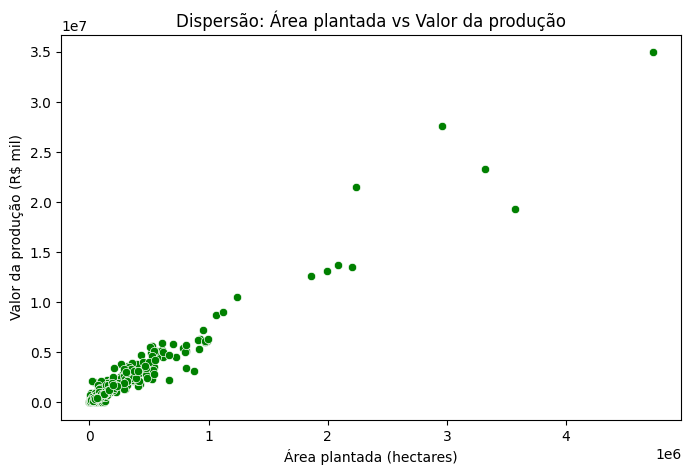

[Item 4a] Interpretação: a nuvem de pontos indica relação linear positiva e muito forte entre as variáveis.
A maioria das microrregiões tem áreas e valores baixos, e poucas, muito grandes, exercem forte influência (pontos de alavanca) sobre a relação.

[Item 4b] Covariância: 1,183,618,264,380.05 | Correlação de Pearson: 0.9753 (p-valor = 0.00e+00)
Interpretação: a covariância positiva indica que as variáveis variam no mesmo sentido; sua magnitude depende das unidades (ha x mil R$), por isso a intensidade é lida pela correlação: muito forte (r = 0.9753).


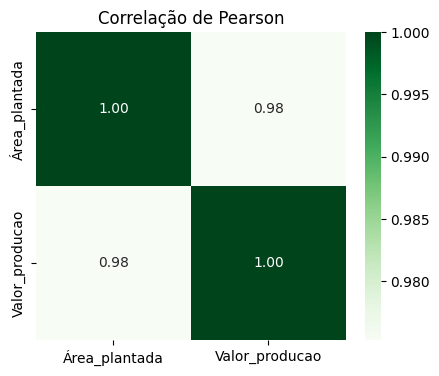

[Item 4c] Interpretação: o mapa de calor confirma a correlação positiva muito forte (r = 0.98).


In [6]:
x = df['Área_plantada']
y = df['Valor_producao']
cov_xy = np.cov(x, y)[0, 1]
r, p_r = stats.pearsonr(x, y)
sentido = 'positiva' if r > 0 else 'negativa'

# a) Gráfico de dispersão
plt.figure(figsize=(8, 5))
sns.scatterplot(x=x, y=y, color='green')
plt.title('Dispersão: Área plantada vs Valor da produção')
plt.xlabel('Área plantada (hectares)')
plt.ylabel('Valor da produção (R$ mil)')
plt.show()
print(f'[Item 4a] Interpretação: a nuvem de pontos indica relação linear {sentido} e {forca_correlacao(r)} entre as variáveis.')
if max(x.skew(), y.skew()) > 1:
    print('A maioria das microrregiões tem áreas e valores baixos, e poucas, muito grandes, exercem forte influência (pontos de alavanca) sobre a relação.')

# b) Covariância e correlação de Pearson
print(f'\n[Item 4b] Covariância: {cov_xy:,.2f} | Correlação de Pearson: {r:.4f} (p-valor = {p_r:.2e})')
mesmo_sentido = 'no mesmo sentido' if r > 0 else 'em sentidos opostos'
print(f'Interpretação: a covariância {sentido} indica que as variáveis variam {mesmo_sentido}; sua magnitude depende das '
      f'unidades (ha x mil R$), por isso a intensidade é lida pela correlação: {forca_correlacao(r)} (r = {r:.4f}).')

# c) Gráfico de correlação de Pearson
plt.figure(figsize=(5, 4))
sns.heatmap(df[['Área_plantada', 'Valor_producao']].corr(), annot=True, cmap='Greens', fmt='.2f')
plt.title('Correlação de Pearson')
plt.show()
print(f'[Item 4c] Interpretação: o mapa de calor confirma a correlação {sentido} {forca_correlacao(r)} (r = {r:.2f}).')

[Item 4d] Equação da reta: Valor_producao = 74,039.37 + 7.1057 x Área_plantada
Interpretação: cada hectare adicional plantado está associado a uma variação média de R$ 7,105.72 no valor da produção.


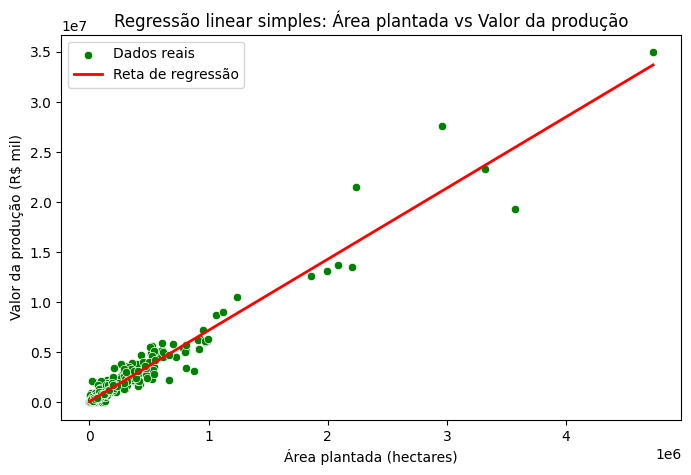


[Item 4e] R² = 0.9512 | F = 10,773.46 | p-valor (F) = 0.00e+00
Interpretação: a área plantada explica 95.12% da variação do valor da produção. O teste F é significativo (p < 0,05): o modelo é globalmente adequado, ou seja, a área plantada tem efeito linear significativo sobre o valor.

[Item 4f] Previsão para 5,000 ha plantados: R$ 109,567.97 mil (valor estimado da produção)


In [7]:
# d) Regressão linear simples
reg_simples = LinearRegression().fit(x.to_frame(), y)
b0, b1 = reg_simples.intercept_, reg_simples.coef_[0]
print(f'[Item 4d] Equação da reta: Valor_producao = {b0:,.2f} + {b1:.4f} x Área_plantada')
print(f'Interpretação: cada hectare adicional plantado está associado a uma variação média de R$ {b1 * 1000:,.2f} no valor da produção.')

xs = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=x, y=y, color='green', label='Dados reais')
plt.plot(xs, b0 + b1 * xs, color='red', linewidth=2, label='Reta de regressão')
plt.title('Regressão linear simples: Área plantada vs Valor da produção')
plt.xlabel('Área plantada (hectares)')
plt.ylabel('Valor da produção (R$ mil)')
plt.legend()
plt.show()

# e) Adequação do modelo: R² e teste F
r2 = r2_score(y, reg_simples.predict(x.to_frame()))
f_stat, p_f = teste_f(r2, n=len(x), k=1)
print(f'\n[Item 4e] R² = {r2:.4f} | F = {f_stat:,.2f} | p-valor (F) = {p_f:.2e}')
print(f'Interpretação: a área plantada explica {r2:.2%} da variação do valor da produção. ', end='')
print('O teste F é significativo (p < 0,05): o modelo é globalmente adequado, ou seja, a área plantada tem efeito linear significativo sobre o valor.' if p_f < 0.05
      else 'O teste F não é significativo (p >= 0,05): não há evidência de que o modelo seja adequado.')

# f) Previsão
area_nova = 5000
previsao = reg_simples.predict(pd.DataFrame({'Área_plantada': [area_nova]}))[0]
print(f'\n[Item 4f] Previsão para {area_nova:,} ha plantados: R$ {previsao:,.2f} mil (valor estimado da produção)')

### 5. Regressão linear múltipla

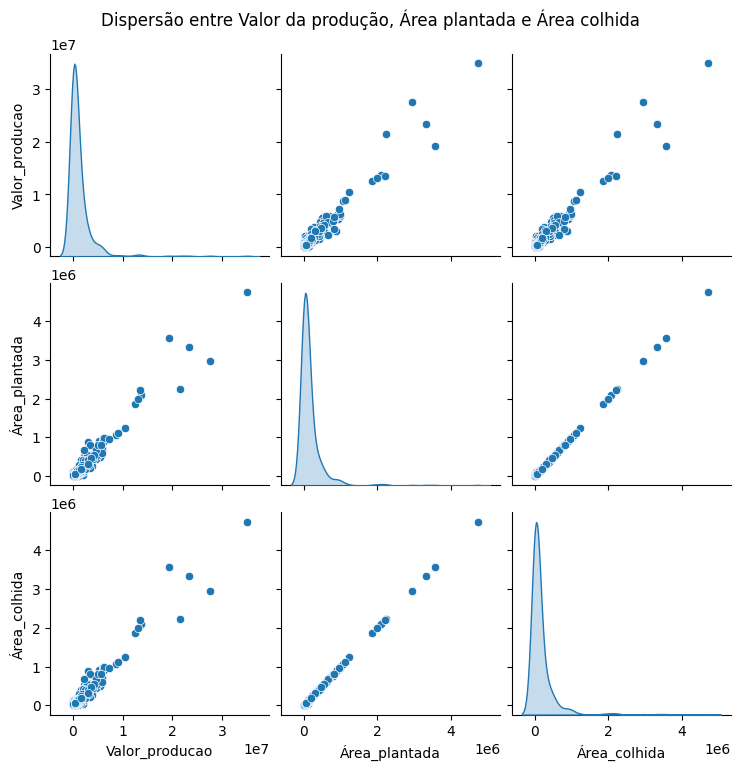

[Item 5b] Matriz de covariância:
                Valor_producao  Área_plantada  Área_colhida
Valor_producao    8.842166e+12   1.183618e+12  1.184516e+12
Área_plantada     1.183618e+12   1.665726e+11  1.666510e+11
Área_colhida      1.184516e+12   1.666510e+11  1.667648e+11

Matriz de correlação de Pearson:
                Valor_producao  Área_plantada  Área_colhida
Valor_producao          1.0000         0.9753        0.9755
Área_plantada           0.9753         1.0000        0.9999
Área_colhida            0.9755         0.9999        1.0000


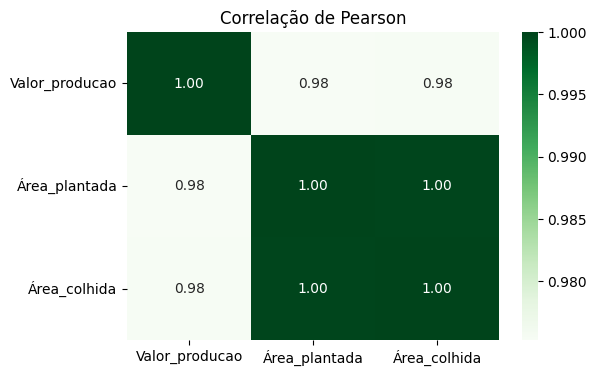

[Itens 5a-c] Interpretação: o valor da produção tem correlação muito forte com a área plantada (r = 0.9753) e muito forte com a área colhida (r = 0.9755). As duas áreas têm correlação muito forte entre si (r = 0.9999), o que antecipa redundância entre as variáveis explicativas.


In [8]:
vars_m = ['Valor_producao', 'Área_plantada', 'Área_colhida']

# a) Gráfico de dispersão múltiplo
g = sns.pairplot(df[vars_m], diag_kind='kde')
g.fig.suptitle('Dispersão entre Valor da produção, Área plantada e Área colhida', y=1.02)
plt.show()

# b) Matrizes de covariância e de correlação
cov_m = df[vars_m].cov()
corr_m = df[vars_m].corr()
print('[Item 5b] Matriz de covariância:')
print(cov_m)
print('\nMatriz de correlação de Pearson:')
print(corr_m.round(4))

# c) Gráfico de correlação
plt.figure(figsize=(6, 4))
sns.heatmap(corr_m, annot=True, cmap='Greens', fmt='.2f')
plt.title('Correlação de Pearson')
plt.show()

r_vp = corr_m.loc['Valor_producao', 'Área_plantada']
r_vc = corr_m.loc['Valor_producao', 'Área_colhida']
r12 = corr_m.loc['Área_plantada', 'Área_colhida']
print(f'[Itens 5a-c] Interpretação: o valor da produção tem correlação {forca_correlacao(r_vp)} com a área plantada (r = {r_vp:.4f}) '
      f'e {forca_correlacao(r_vc)} com a área colhida (r = {r_vc:.4f}). As duas áreas têm correlação {forca_correlacao(r12)} entre si '
      f'(r = {r12:.4f}), o que antecipa redundância entre as variáveis explicativas.')

In [9]:
# d) Equação da regressão linear múltipla
X_mult = df[['Área_plantada', 'Área_colhida']]
reg_mult = LinearRegression().fit(X_mult, y)
c0, (c1, c2) = reg_mult.intercept_, reg_mult.coef_
print(f'[Item 5d] Valor_producao = {c0:,.2f} + ({c1:.4f} x Área_plantada) + ({c2:.4f} x Área_colhida)')

# e) Adequação do modelo: R², R² ajustado, teste F e multicolinearidade
n, k = len(df), 2
r2_m = r2_score(y, reg_mult.predict(X_mult))
r2_aj = 1 - (1 - r2_m) * (n - 1) / (n - k - 1)
f_m, p_fm = teste_f(r2_m, n, k)
vif = 1 / (1 - r12 ** 2)
print(f'\n[Item 5e] R² = {r2_m:.4f} | R² ajustado = {r2_aj:.4f} | F = {f_m:,.2f} | p-valor (F) = {p_fm:.2e} | VIF = {vif:,.1f}')
print(f'Interpretação: as áreas plantada e colhida explicam {r2_m:.2%} da variação do valor da produção. ', end='')
print('O teste F é significativo (p < 0,05): o modelo é globalmente adequado.' if p_fm < 0.05
      else 'O teste F não é significativo (p >= 0,05): o modelo não é adequado.')
if vif > 10:
    print('O VIF indica multicolinearidade severa: os coeficientes individuais são instáveis (podem ter sinais contraintuitivos) '
          'e não devem ser lidos isoladamente; o modelo serve para prever o valor com as duas áreas em conjunto.')

# f) Previsão com 2 variáveis explicativas
novo = pd.DataFrame({'Área_plantada': [4000], 'Área_colhida': [3800]})
previsao_m = reg_mult.predict(novo)[0]
print(f'\n[Item 5f] Previsão para 4.000 ha plantados e 3.800 ha colhidos: R$ {previsao_m:,.2f} mil')

[Item 5d] Valor_producao = 86,465.52 + (-2.4928 x Área_plantada) + (9.5940 x Área_colhida)

[Item 5e] R² = 0.9515 | R² ajustado = 0.9514 | F = 5,420.13 | p-valor (F) = 0.00e+00 | VIF = 4,694.8
Interpretação: as áreas plantada e colhida explicam 95.15% da variação do valor da produção. O teste F é significativo (p < 0,05): o modelo é globalmente adequado.
O VIF indica multicolinearidade severa: os coeficientes individuais são instáveis (podem ter sinais contraintuitivos) e não devem ser lidos isoladamente; o modelo serve para prever o valor com as duas áreas em conjunto.

[Item 5f] Previsão para 4.000 ha plantados e 3.800 ha colhidos: R$ 112,951.55 mil


### 6. Regressão logística binária

In [10]:
# Variável resposta: 1 = valor da produção acima da mediana (alto valor); 0 = caso contrário
mediana_valor = df['Valor_producao'].median()
y_bin = (df['Valor_producao'] > mediana_valor).astype(int)
X_log = df[['Área_plantada', 'Área_colhida']]

# Padroniza as áreas para o ajuste convergir; os coeficientes voltam à escala original (hectares)
scaler = StandardScaler().fit(X_log)
modelo = LogisticRegression(C=1e10, max_iter=1000).fit(scaler.transform(X_log), y_bin)  # C muito alto = sem regularização
coef = modelo.coef_[0] / scaler.scale_
intercepto = modelo.intercept_[0] - np.sum(coef * scaler.mean_)

# a) Equação da regressão logística
print('[Item 6a] ln(p / (1 - p)) = '
      f'{intercepto:.4f} + ({coef[0]:.3e} x Área_plantada) + ({coef[1]:.3e} x Área_colhida)')
print('          p = P(alto valor) = 1 / (1 + e^(-z)), em que z é o lado direito da equação acima')

# b) Matriz de confusão e acurácia
pred = modelo.predict(scaler.transform(X_log))
cm = confusion_matrix(y_bin, pred)
print('\n[Item 6b] Matriz de confusão:')
display(pd.DataFrame(cm, index=['Real: baixo valor', 'Real: alto valor'], columns=['Previsto: baixo valor', 'Previsto: alto valor']))
acuracia = accuracy_score(y_bin, pred)
baseline = max(y_bin.mean(), 1 - y_bin.mean())
tn, fp, fn, tp = cm.ravel()
print(f'Acurácia: {acuracia:.2%} (classificar tudo na classe mais frequente acertaria {baseline:.2%})')
print(f'Interpretação: o modelo acertou {tn + tp} de {len(y_bin)} microrregiões; errou {fp} ao prever alto valor para regiões de baixo valor '
      f'(falsos positivos) e {fn} ao prever baixo valor para regiões de alto valor (falsos negativos).')

# c) Classificação de um novo caso com 2 variáveis explicativas
novo_caso = pd.DataFrame({'Área_plantada': [4500], 'Área_colhida': [4400]})
prob = modelo.predict_proba(scaler.transform(novo_caso))[0, 1]
classe = 'alto valor' if prob >= 0.5 else 'baixo valor'
print(f'\n[Item 6c] Microrregião com 4.500 ha plantados e 4.400 ha colhidos: P(alto valor) = {prob:.4f} -> classificada como {classe}')

[Item 6a] ln(p / (1 - p)) = -3.4601 + (-3.073e-05 x Área_plantada) + (1.047e-04 x Área_colhida)
          p = P(alto valor) = 1 / (1 + e^(-z)), em que z é o lado direito da equação acima

[Item 6b] Matriz de confusão:


,Previsto: baixo valor,Previsto: alto valor
Real: baixo valor,263,15
Real: alto valor,31,246


Acurácia: 91.71% (classificar tudo na classe mais frequente acertaria 50.09%)
Interpretação: o modelo acertou 509 de 555 microrregiões; errou 15 ao prever alto valor para regiões de baixo valor (falsos positivos) e 31 ao prever baixo valor para regiões de alto valor (falsos negativos).

[Item 6c] Microrregião com 4.500 ha plantados e 4.400 ha colhidos: P(alto valor) = 0.0416 -> classificada como baixo valor


### Conclusões e limitações

**Leitura geral.** As análises avaliam como a área cultivada se associa ao valor da produção agrícola das microrregiões e se esse valor pode ser previsto e classificado a partir das áreas plantada e colhida. Os valores de correlação, R², testes F e acurácia estão nas seções 4 a 6 e devem ser lidos como **associação estatística**, não como relação de causa e efeito.

**Limitações:**

- **Normalidade:** os itens 2 e 3 assumem distribuição normal, conforme o enunciado, mas o valor da produção e as áreas são assimétricos à direita (poucas microrregiões muito grandes), então as probabilidades são aproximações.
- **Teste de hipóteses:** as amostras são retiradas da própria base de referência, então H0 vale por construção; o teste ilustra o procedimento e não compara populações distintas.
- **Pontos de alavanca:** poucas microrregiões de grande escala influenciam fortemente correlação e retas de regressão; o R² alto não garante bom ajuste para regiões pequenas.
- **Multicolinearidade:** as áreas plantada e colhida são quase redundantes entre si, o que torna instáveis os coeficientes individuais das regressões múltipla e logística.
- **Avaliação do modelo logístico:** a acurácia foi calculada na mesma base usada no ajuste, sem separação treino/teste, e tende a ser otimista.
- **Escopo dos dados:** recorte único de produto e ano (ver cabeçalho do arquivo), valores nominais e agregados por microrregião; os resultados não valem para propriedades ou municípios individuais nem para outros anos.
- **Variáveis disponíveis:** a base tem apenas três variáveis numéricas; fatores como clima, tipo de cultura, preço, infraestrutura e acesso a crédito não entram no modelo.